# 信号处理 ― signal 模块

## 本章要学什么

`signal` 模块里有整理信号、设计滤波器、计算系统响应这几类函数，这一章用例子确认下面的内容。

- 用中值滤波与顺序滤波去掉噪声
- 设计 IIR 滤波器并确认频率响应
- 用扫频波测量滤波器的特性
- 用 `lti` 表示连续时间线性系统并计算响应
- 通过传递函数的运算，组装 PI 控制与 PID 控制

In [1]:
from matplotlib import pyplot as plt

import helper.matplotlib
import numpy as np
from scipy import signal

## 中值滤波

中值滤波用来去掉语音里瞬间的噪声、或者图像里的椒盐噪声：`signal.medfilt()` 作用于一维信号，`signal.medfilt2d()` 作用于二维信号；多维图像还可以用 `scipy.ndimage` 里的中值滤波。这里看 `medfilt()` 的作用。

True


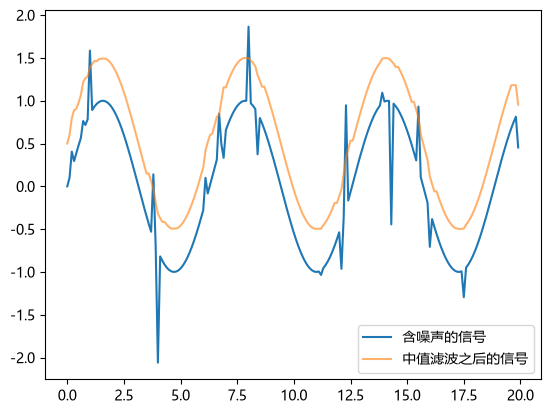

In [2]:
t = np.arange(0, 20, 0.1)
x = np.sin(t)
x[np.random.randint(0, len(t), 20)] += np.random.standard_normal(20) * 0.6  #❶ 瞬时噪声
x2 = signal.medfilt(x, 5)  #❷ 窗口宽度 5 的中值滤波
x3 = signal.order_filter(x, np.ones(5), 2)   # 用顺序滤波也得到相同结果
print(np.all(x2 == x3))
plt.plot(t, x, label="含噪声的信号")
plt.plot(t, x2 + 0.5, alpha=0.6, label="中值滤波之后的信号")
plt.legend(loc="best")
plt.show()

❶ 在正弦波上加上若干位置随机的瞬时噪声。❷ 用 `medfilt()` 做中值滤波，第 2 个参数是求中值的窗口宽度、必须是奇数，`medfilt()` 把每一点换成该窗口内的中值。

最后把原信号与滤波后的信号画出来，为了便于比较，把滤波后的信号整体上移了 0.5。从图上可以看出，只有那些尖锐的噪声被去掉了。

中值滤波是顺序滤波的一个特例：顺序滤波把窗口内的值从小到大排好，再换成指定名次上的那个值，调用形式如下。

```text
order_filter(a, domain, rank)
```

其中 `a` 是多维数组，`domain` 是决定窗口形状的数组，`rank` 是排序之后的名次，0 是最小值、1 是第二小的值。窗口宽度为 5 时，`rank=2` 就是中值，因此与 `medfilt(x, 5)` 的结果相同。

## IIR 滤波器的设计

`signal` 模块里有很多设计滤波器的函数，这里设计一个 IIR 带通滤波器、确认它的频率响应，最后再让扫频波通过这个滤波器。

In [3]:
sampling_rate = 8000.0

# 设计带通滤波器
# 通带是 0.2*4000 〜 0.5*4000，阻带在 0.1*4000 以下与 0.6*4000 以上
# 通带起伏 2dB，阻带衰减 40dB
b, a = signal.iirdesign([0.2, 0.5], [0.1, 0.6], 2, 40)  #❶

w, h = signal.freqz(b, a)                                  #❷ 周波数応答

power = 20 * np.log10(np.clip(np.abs(h), 1e-8, 1e100))     #❸ 增益(dB)
freq = w / np.pi * sampling_rate / 2                       #❹ 周波数(Hz)

❶ 用 `iirdesign()` 设计 IIR 带通滤波器：通带是 $0.2 f_0$ 到 $0.5 f_0$，阻带在 $0.1 f_0$ 以下与 $0.6 f_0$ 以上，其中 $f_0$ 是采样频率的一半，8kHz 采样时 $f_0=4$kHz，也就是通带为 800Hz 到 2kHz；通带的起伏是 2dB，阻带的衰减在 40dB 以上。

`iirdesign()` 返回 IIR 滤波器分子与分母的系数 `b` 和 `a`，其中 `a[0]` 总是 1。

❷ 用 `freqz()` 计算滤波器的频率响应，返回 `w` 与 `h` 两个结果：`w` 是角频率，用 $\omega f_0/\pi$ 就换算成实际频率；`h` 是各频率上的响应、取值是复数，其绝对值是增益特性、辐角是相位特性。

❸ 由 `h` 的绝对值算出以 dB 表示的增益，由于 `h` 里会有接近 0 的值，所以先用 `clip()` 加上下限再取对数，❹ 把频率换算成 Hz，画出增益特性。

在实际系统里，常给系统输入扫频波、看它的输出来测量频率特性，下面的代码就模拟这个过程。

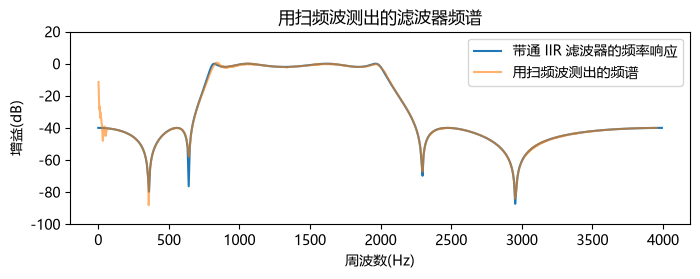

In [4]:
# 生成 8kHz 采样、2 秒的扫频波，从 0Hz 升到 sampling_rate/2
t_sweep = np.arange(0, 2, 1 / sampling_rate)                   #❶
sweep = signal.chirp(t_sweep, f0=0, t1=2, f1=sampling_rate / 2)  #❷
out = signal.lfilter(b, a, sweep)                              #❸ 通过滤波器
out_db = 20 * np.log10(np.abs(out))                            #❹ 把振幅换成 dB
index = signal.argrelmax(out_db, order=3)                      #❺ 局所最大値

plt.figure(figsize=(8, 2.5))
plt.plot(freq, power, label="带通 IIR 滤波器的频率响应")
plt.plot(
    t_sweep[index] / 2.0 * 4000,
    out_db[index],
    label="用扫频波测出的频谱",
    alpha=0.6,
)  #❻
plt.legend(loc="best")
plt.title("用扫频波测出的滤波器频谱")
plt.ylim(-100, 20)
plt.ylabel("增益(dB)")
plt.xlabel("周波数(Hz)")
plt.show()

❶ 先做出传给 `chirp()` 的时间数组，这里是 8kHz 采样的 2 秒，❷ 用 `chirp()` 生成从 0Hz 用 2 秒升到 4kHz 的扫频波，❸ 用 `lfilter()` 让这个波通过滤波器。

❹ 因为想求输出的包络，先把振幅换成 dB，❺ 用 `argrelmax()` 求 `out_db` 的局部极大值位置，其中 `order=3` 表示只在前后 3 点共 7 点里选出最大值。❻ 把时间换算成频率，画出这些局部极大点。

从图上看，`freqz()` 算出的特性与用扫频波测出的特性是一致的。

## 连续时间的线性系统

上一章用 `odeint()` 对质量-弹簧-阻尼系统的微分方程做了数值积分，这个系统的式子是 $m \ddot{x} + b \dot{x} + k x = f$。做拉普拉斯变换之后，微分方程就变成了代数方程。

$$m s^2 X(s) + b s X(s) + k X(s) = F(s)$$

其中 $F(s)$ 是输入、$X(s)$ 是输出，$n$ 阶微分对应 $s^n$，整理成输入输出的形式，就得到传递函数 $P(s)$。

$$P(s) = \frac{X(s)}{F(s)} = \frac{1}{m s^2 + b s + k}$$

连续时间系统的传递函数是 $s$ 的多项式之比，有了传递函数就能算出输入对应的输出。下面的例子计算给质量-弹簧-阻尼系统输入阶跃信号与正弦波时的响应。

❶ 建立 `lti` 对象，这里用传递函数的分子与分母系数来表示；系数的排列遵循 `numpy.poly1d` 的规则，开头是最高次。❷ 用 `lti.step()` 计算阶跃响应，`T` 是计算响应的时间数组。❸ 用 `signal.lsim()` 计算输入正弦波时的响应，第 1 个参数是 `lti` 对象或者 `(分子, 分母)` 的元组，`U` 是输入的数组。

`step()` 与 `lsim()` 返回值的第 2 个就是系统的输出。

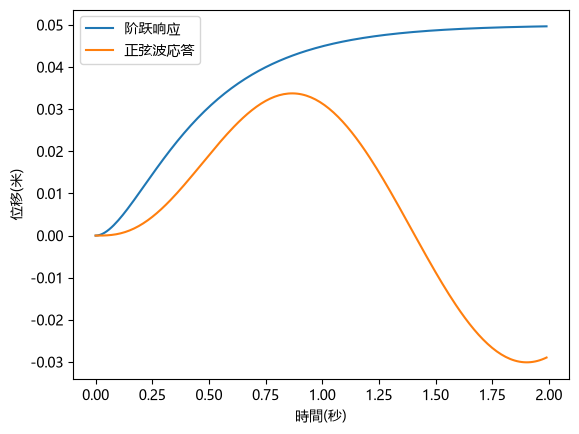

In [5]:
m, b, k = 1.0, 10, 20

numerator = [1]
denominator = [m, b, k]

plant = signal.lti(numerator, denominator)  #❶

t = np.arange(0, 2, 0.01)
_, x_step = plant.step(T=t)  #❷ 阶跃响应
_, x_sin, _ = signal.lsim(plant, U=np.sin(np.pi * t), T=t)  #❸ 正弦波応答

plt.plot(t, x_step, label="阶跃响应")
plt.plot(t, x_sin, label="正弦波応答")
plt.legend(loc="best")
plt.xlabel("時間(秒)")
plt.ylabel("位移(米)")
plt.show()

从图上可以看出，阶跃响应最终稳定在 $x=0.05$，此时 $k x = 1$。

利用传递函数的四则运算，可以表示多个系统组合起来的系统，例如两个系统串联的传递函数就是各自传递函数之积。传递函数是多项式之比，所以能用 `numpy.poly1d` 的函数来计算。

下面的 `SYS` 类定义了 `__mul__`、`__add__`、`__truediv__` 等方法，使传递函数可以像数一样做四则运算。

![反馈控制系统的框图](images/feedback_system.png)

❶ `feedback()` 返回反馈系统的传递函数。图中 $P$ 是被控对象、$C$ 是控制器，而 $C$ 的输入是目标值与实际值之差 $x_r - x$，从 $x_r$ 到 $x$ 的传递函数就是这个反馈系统的传递函数。由框图可以写出下面的式子。

$$X(s) = (X_r(s) - X(s)) \cdot C(s) \cdot P(s)$$

整理之后得到下面这样。

$$\frac{X(s)}{X_r(s)} = \frac{C(s) \cdot P(s)}{1 + C(s) \cdot P(s)}$$

把 $C(s) \cdot P(s)$ 记作 $Y(s)$，反馈系统的传递函数就是 $\frac{Y(s)}{1 + Y(s)}$。

❷ 为了让 `SYS` 对象能作为第 1 个参数传给 `step()` 与 `lsim()`，这里定义 `__iter__()`，依次返回分子与分母的系数。

In [6]:
from numbers import Real


def as_sys(s):
    """传入数值时，当作常数传递函数处理。"""
    if isinstance(s, Real):
        return SYS([s], [1])
    return s


class SYS(object):
    def __init__(self, num, den):
        self.num = num
        self.den = den

    def feedback(self):  #❶
        return self / (self + 1)

    def __mul__(self, s):
        s = as_sys(s)
        num = np.polymul(self.num, s.num)
        den = np.polymul(self.den, s.den)
        return SYS(num, den)

    def __add__(self, s):
        s = as_sys(s)
        den = np.polymul(self.den, s.den)
        num = np.polyadd(np.polymul(self.num, s.den), np.polymul(s.num, self.den))
        return SYS(num, den)

    def __radd__(self, s):      # 支持 1 + SYS(...) 这种写法
        return self + s

    def __truediv__(self, s):
        s = as_sys(s)
        return self * SYS(s.den, s.num)

    def __iter__(self):  #❷
        return iter((self.num, self.den))

下面的例子用 `SYS` 类做出 PI 控制器，计算控制质量-弹簧-阻尼系统时的阶跃响应，PI 控制器的传递函数如下。

$$C = \frac{K_p s + K_i}{s} $$

上一章的 PI 控制器是离散时间的，积分器用累加器近似；这里改用连续时间的传递函数来搭控制系统。

❶ 被控对象的传递函数记作 `plant`，❷ PI 控制器的传递函数记作 `pi_ctrl`；分母的常数项为 0 会让 `step()` 抛出 `LinAlgError`，所以这里放进一个非常小的值。❸ 算出反馈系统的传递函数。

$K_i=0$ 时，输出与目标值之间会留下一定的差；把 $K_p$ 调大差会变小，但会出现过冲(overshoot)。调好 $K_p$ 与 $K_i$ 能减少过冲，不过仍有瞬间略微超过目标值的现象。

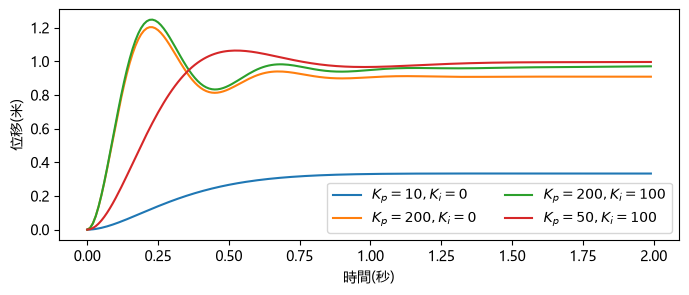

In [7]:
M, b, k = 1.0, 10, 20
plant = SYS([1], [M, b, k])  #❶

pi_settings = [(10, 1e-10), (200, 1e-10), (200, 100), (50, 100)]

fig, ax = plt.subplots(figsize=(8, 3))

for pi_setting in pi_settings:
    pi_ctrl = SYS(pi_setting, [1, 1e-6])  #❷
    feedback = (pi_ctrl * plant).feedback()  #❸
    _, x = signal.step(feedback, T=t)
    label = "$K_p={:d}, K_i={:3.0f}$".format(*pi_setting)
    ax.plot(t, x, label=label)

ax.legend(loc="best", ncol=2)
ax.set_xlabel("時間(秒)")
ax.set_ylabel("位移(米)")
plt.show()

要求出作用在质量上的力，可以把误差信号传给 `lsim()`，算出控制器的输出。

In [8]:
_, f, _ = signal.lsim(pi_ctrl, U=1 - x, T=t)

要把过冲完全消掉，就得改用 PID 控制，PID 控制器的传递函数如下。

$$C = \frac{K_d s^2 + K_p s + K_i}{s} $$

下面的代码计算用 PID 控制器搭出的反馈系统的阶跃响应。由于 PID 会对输入信号微分，对阶跃输入来说，输出会出现宽度几乎为 0、幅度却极大的脉冲。

In [9]:
kd, kp, ki = 30, 200, 400
pid_ctrl = SYS([kd, kp, ki], [1, 1e-6])
feedback = (pid_ctrl * plant).feedback()
_, x2 = signal.step(feedback, T=t)

为了让控制器的输出落在现实的范围内，在反馈系统前面加一个低通滤波器。一阶低通滤波器的传递函数是 $\frac{1}{a \cdot s + 1}$；加上它之后，进入 PID 控制器的输入就变得平滑了。

![带低通滤波器的反馈控制系统框图](images/feedback_system_lp.png)

In [10]:
lp = SYS([1], [0.2, 1])
lp_feedback = lp * (pid_ctrl * plant).feedback()
_, x3 = signal.step(lp_feedback, T=t)

PID 控制器的传递函数分子次数比母次数高，所以没法直接用 `lsim()` 计算响应。为此这里改以 $x_r$ 为输入、$f$ 为输出，求从 $x_r$ 到 $f$ 的传递函数，由下面的式子，

$$ F(s) = (X_r(s) \cdot LP(s) - F(s) \cdot P(s)) \cdot C(s)$$

传递函数就是下面这样。

$$\frac{F(s)}{X_r(s)} = \frac{C(s) \cdot LP(s)}{C(s) \cdot P(s) + 1}$$

再按这个式子计算控制器的输出。

In [11]:
pid_out = (pid_ctrl * lp) / (pid_ctrl * plant + 1)
_, f3 = signal.step(pid_out, T=t)

最后把 PI 控制、PID 控制、以及带低通滤波器的 PID 控制这三种情况下的位移与控制力并排放在一起。PID 控制的力里含有脉冲，图上画不清楚；从位移曲线上可以看出，低通滤波器抑制了过冲。

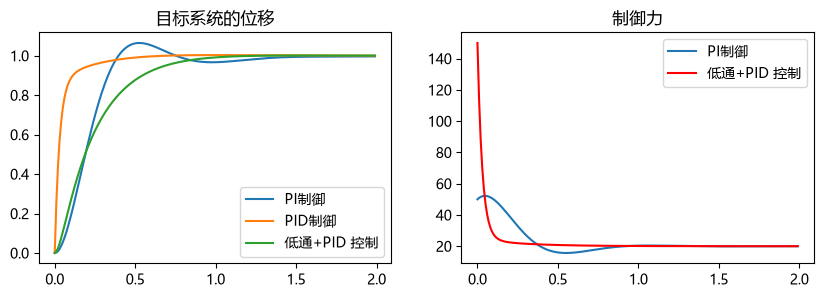

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(t, x, label="PI制御")
ax1.plot(t, x2, label="PID制御")
ax1.plot(t, x3, label="低通+PID 控制")
ax2.plot(t, f, label="PI制御")
ax2.plot(t, f3, color="r", label="低通+PID 控制")
ax1.legend(loc="best")
ax2.legend(loc="best")
ax1.set_title("目标系统的位移")
ax2.set_title("制御力")
plt.show()

## 小结

* 中值滤波用 `medfilt()`，想指定名次时用 `order_filter()`。
* IIR 滤波器用 `iirdesign()` 设计，再用 `freqz()` 确认频率响应。
* 用 `chirp()` 生成扫频波，让它通过 `lfilter()`，就能测出系统的频率特性。
* 连续时间的系统用 `lti` 表示，用 `step()` 与 `lsim()` 计算响应。
* 传递函数是多项式之比，所以能用 `polymul()` 与 `polyadd()` 组装四则运算。
* 反馈系统的传递函数是 $\frac{Y}{1+Y}$，PI 控制的过冲可以用带低通滤波器的 PID 抑制。